# **MMME4125 2026/2027 Coursework**

**Student Name:** Samuel Griffiths

**Student ID:** 20457187

# **Project Description**

In this coursework, you will analise historical data and build your own machine learning pipeline demonstrating your knowledge on data exploration, data preparation and machine learning model development to solve a prediction or classification task  of an engineering domain problem.

**Dataset:** You will select a data set from a range of data sets provided in this module's Moodle page.

**Overall task:** Utilising your selected data set, you will build at least two models of your choice either for regression or classification (depending on the data set you selected) from the ones covered during lectures (e.g. NN, Decision Trees, Randon Forest, CNN to name a few examples). Employ appropriate methods from the pandas, matplotlib, keras and sklearn libraries to analyse and process the dataset and for building predictive models.

**Note:** You must use only pandas, numpy, matplotlib, keras and sklearn or any other specific library that was covered during class for example for data augmentation. Do not use other libraries or external packages. Use of such packages may receive zero credit for the affected parts. 

**Format:** Use this Jupyter Notebook as a template to write your report/answers to questions in Markdown cells, supported by your source code in Code cells.

The project (and this notebook) are structured in three main tasks:

**(Task 1)** -  Data set selection & data exploration : Once you select the data set you will carry out an initial Exploratory Data Analysis (EDA). Some data sets might be too large, containing multiple features or measurements of multiple variables. As you explore your data, you will make a decision of which sub set of your data you will use for your prediction/classification task. **You will then discuss this decision with your lab tutor (you will book a slot for this during lab hours) and get feedback**. As it will be indicated later in this notebook, you will add as markdown your analysis of the EDA results, the feedback provided by the tutor and how this has been taken into account to move to the next task. 

**(Task 2)** - Data preparation : with your chosen dataset (or subset), you will carry out the data preparation. This will include data visualisation (e.g. patterns, class imbalance, outliers), dealing with any missing values, outlier handling, scaling/normalisation, feature extraction, data reduction/augmentation, creating of training,validaton and test sets). 

**(Task 3)** - Model Development & Metrics Analysis : once your data set is ready, select two ML approaches from the ones covered during the lectures and discuss your selection with your lab tutor (**you will need to book a second lab slot for this and get feedback**). You will add in a Markdown cell your rationale for chosing such models, providing details of the feedback provided by the lab tutor and how it was used to move forward. Additional rationale for the specific hyper-parameters should also be included. Implementation should be added in a Code cell with appropriate code comments. Appropriate metrics for the model used should be implemented and presented (e.g. RMSE, Precision, Recall, F-Score, confusion matrix). You may want to try multiple hyper parameters to understand how the model behaves and if further iprovement can be obtained. In a Markdown cell, please explain the results obtained on both models and present a discussion of results. This discussion should include your insights on how model design/hyper-parameters affected the quality of the results.


Ensure your code produces the corresponding plots or results addressing the questions. Rename this .ipynb file to 202627_MMME4125_cw_XXX.ipynb, where XXX is your username (e.g., psxyz), and submit it to Moodle by **DATE**

**Marks**: The coursework is worth a total of 100 marks (accounting for 70% of the module grade). Marks will be awarded based on your understanding of machine learning theories, the informativeness and presentation of your code, visualisations, results (e.g., code comments, necessary labels in plots) and analysis, evidence of feedback and how it was addressed, your self-learning ability in solving the specific problem, and how succinct and clear your report writing is.

In [1]:
# You can change the import statements as you wish, but you should not use any library beyond pandas, numpy, matplotlib, and sklearn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.io import loadmat

file_path = Path("mill.mat")
if not file_path.exists():
    raise FileNotFoundError(f"Could not find {file_path.resolve()}. Put mill.mat beside this notebook.")

In [2]:
mat = loadmat(file_path, squeeze_me=True, struct_as_record=False)
runs = np.atleast_1d(mat["mill"]).ravel()
print(f"Loaded {len(runs)} machining records")
print("Fields:", runs[0]._fieldnames)

Loaded 167 machining records
Fields: ['case', 'run', 'VB', 'time', 'DOC', 'feed', 'material', 'smcAC', 'smcDC', 'vib_table', 'vib_spindle', 'AE_table', 'AE_spindle']


In [3]:
records = [
    {field: getattr(run, field) for field in run._fieldnames}
    for run in runs
]
df = pd.DataFrame(records)

scalar_cols = ["case", "run", "VB", "time", "DOC", "feed", "material"]
signal_cols = ["smcAC", "smcDC", "vib_table", "vib_spindle", "AE_table", "AE_spindle"]
for column in scalar_cols:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("DataFrame shape:", df.shape)
display(df[scalar_cols].head())

DataFrame shape: (167, 13)


,case,run,VB,time,DOC,feed,material
0,1,1,0.00,2,1.5,0.5,1
1,1,2,NaN,4,1.5,0.5,1
2,1,3,NaN,6,1.5,0.5,1
3,1,4,0.11,7,1.5,0.5,1
4,1,5,NaN,11,1.5,0.5,1


In [4]:
print("Missing scalar values:")
display(df[scalar_cols].isna().sum().to_frame("missing_count"))
print("Signal lengths in the first record:")
print({name: len(df.at[0, name]) for name in signal_cols})

Missing scalar values:


,missing_count
case,0
run,0
VB,21
time,0
DOC,0
feed,0
material,0


Signal lengths in the first record:
{'smcAC': 9000, 'smcDC': 9000, 'vib_table': 9000, 'vib_spindle': 9000, 'AE_table': 9000, 'AE_spindle': 9000}


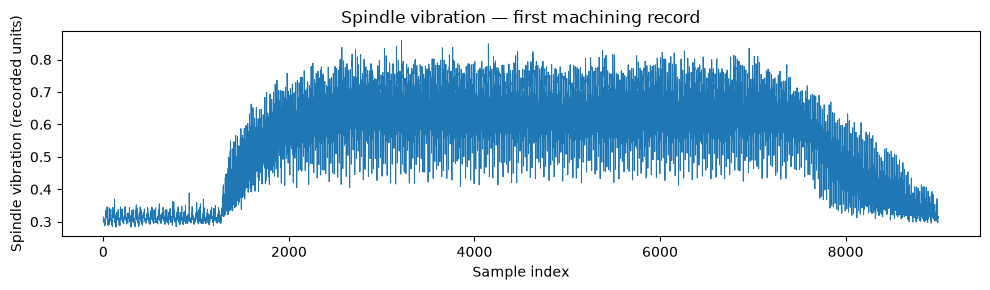

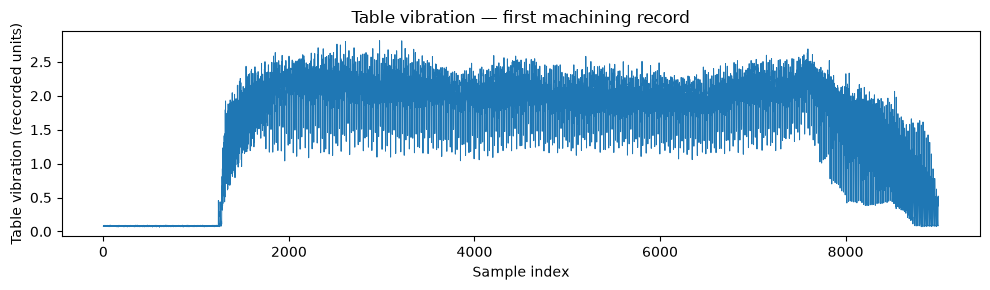

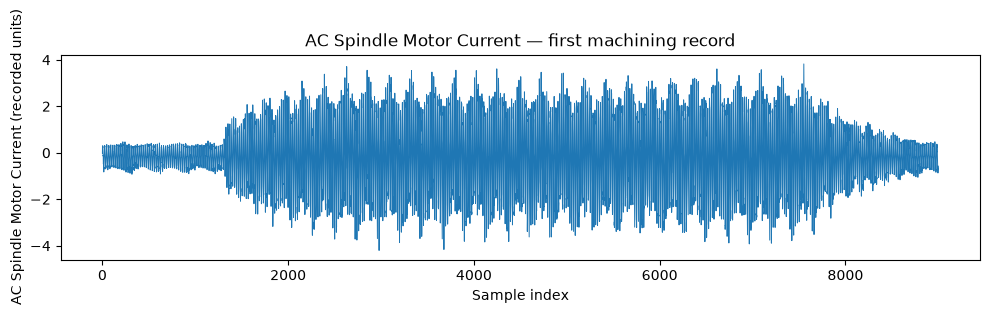

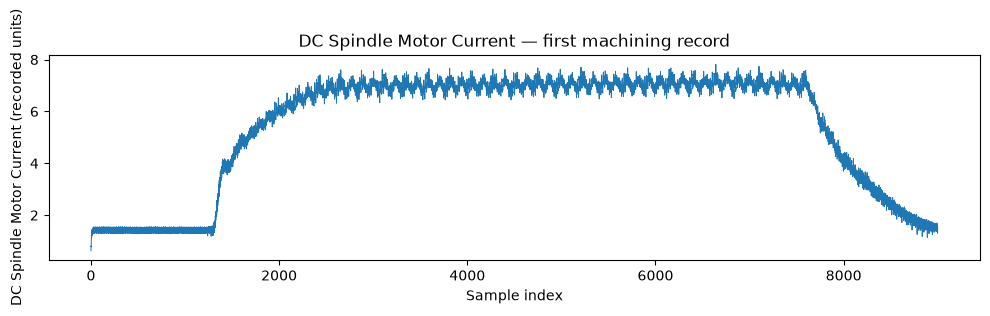

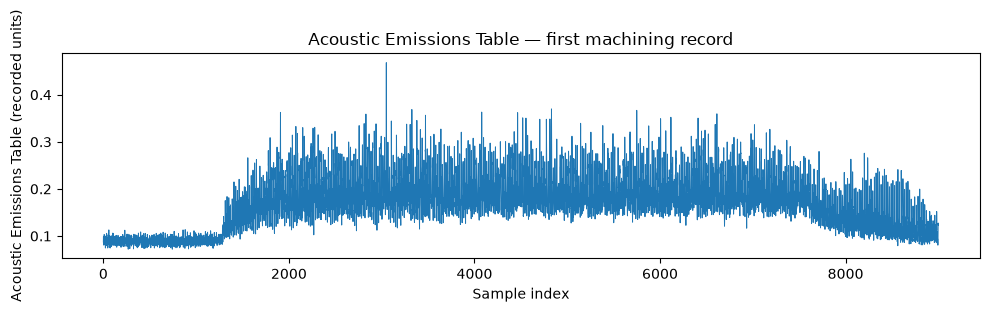

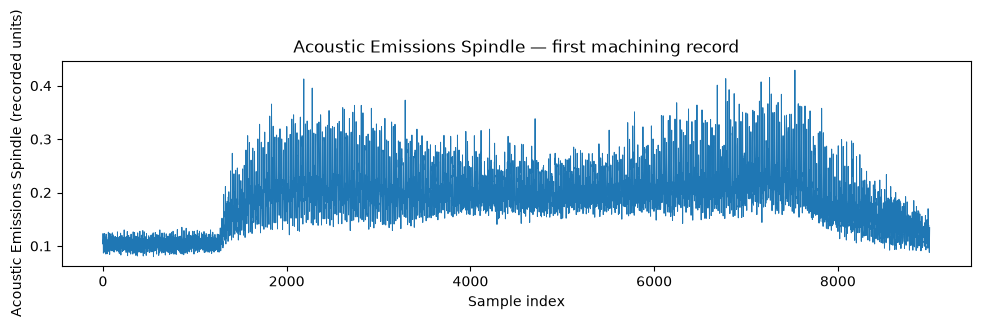

In [5]:
signal = np.asarray(df.at[0, "vib_spindle"]).ravel()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(signal)), signal, linewidth=0.7)
plt.xlabel("Sample index")
plt.ylabel("Spindle vibration (recorded units)")
plt.title("Spindle vibration — first machining record")
plt.tight_layout()
plt.show()

signal = np.asarray(df.at[0, "vib_table"]).ravel()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(signal)), signal, linewidth=0.7)
plt.xlabel("Sample index")
plt.ylabel("Table vibration (recorded units)")
plt.title("Table vibration — first machining record")
plt.tight_layout()
plt.show()

signal = np.asarray(df.at[0, "smcAC"]).ravel()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(signal)), signal, linewidth=0.7)
plt.xlabel("Sample index")
plt.ylabel("AC Spindle Motor Current (recorded units)")
plt.title("AC Spindle Motor Current — first machining record")
plt.tight_layout()
plt.show()

signal = np.asarray(df.at[0, "smcDC"]).ravel()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(signal)), signal, linewidth=0.7)
plt.xlabel("Sample index")
plt.ylabel("DC Spindle Motor Current (recorded units)")
plt.title("DC Spindle Motor Current — first machining record")
plt.tight_layout()
plt.show()

signal = np.asarray(df.at[0, "AE_table"]).ravel()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(signal)), signal, linewidth=0.7)
plt.xlabel("Sample index")
plt.ylabel("Acoustic Emissions Table (recorded units)")
plt.title("Acoustic Emissions Table — first machining record")
plt.tight_layout()
plt.show()

signal = np.asarray(df.at[0, "AE_spindle"]).ravel()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(signal)), signal, linewidth=0.7)
plt.xlabel("Sample index")
plt.ylabel("Acoustic Emissions Spindle (recorded units)")
plt.title("Acoustic Emissions Spindle — first machining record")
plt.tight_layout()
plt.show()

<div class="alert alert-success" style="text-align:left;">
<h2>Task 1. Dataset Selection & Exploratory Data Analysis<span style="float:right;">[25 marks]</span></h2></div>

### Task 1a. <span style="color:red">(10 marks)</span>

Start by introducing the engineering problem that you will be addressing, what the current industrial practice is to solve this problem and why ML is a good approach to solve it (3 marks). Explain the data set you have selected by providing details on what each variable represents, if you suspect there are any likely measurement problems, if there are any variables that could introduce leakage and if any mechanical principles may provide initial plausible relationships across these variables (5 marks).  Finally explain why this is a regression or a classification task (2 marks).

*Task 1a. Write your answer here*

Introduction:
This project addresses the need for a method to monitor and measure tool wear for milling cutters on a CNC milling machine. Numerous variables were measured for tools on a Matsuura MC-510V machining centre, and the tool wear was then measured. This fact defines the problem that needs solving; can the tool wear be estimated accurately so that the tools do not have to be taken out of the machine and the tools can be replaced before they reach their maximum wear value and/or break.

Current industrial practice: 
Currently, the tool wear is measured by hand/experimentally, however, this means that the tool has to be taken out of the machine so that it can be measured. This means more human input is required, and the time that the tool is taken out is not calculated scientifically. This means that the estimation may be incorrect, anxd the tool is taken out too early when it is not worn, increasing the time the machine is stopped and not cutting. However, the tool may be taken out too late, when it has either broken or the cutting surface is worn past the maximum value, which can lead to negative effects on the surface of the part. 

Why is ML a good approach to solve this problem:
ML is a good approach to solve this problem because it can understand what each tool has done and assess the quality of the tool. For example, if one approach is to only quantify tool wear based on how long it has been in the machine, this will not account for times when heavier cuts were taken. This means that two tools that have been in the machine for the same amount of time may have done different amounts of cutting. Therefore, ML can understand these parameters, and quantify/classify the tool wear based on multiple parameters, giving a more accurate estimation, and increasing overall efficiency, reducing cycle times, improving surface finish and reducing costs and lead times.

Explain data set and what each variable represents:
**The data in this set represents experiments from runs on a milling machine under various operating 
conditions, including entry and exit cuts. Data sampled by three different types of sensors (acoustic emission sensor, vibration 
sensor, current sensor) were acquired at several positions. The tool wear was also measured. There are 16 cases with varying number of runs. The number of runs was dependent on the degree of flank wear that was measured between runs at irregular intervals up to a wear limit (and sometimes beyond). Flank wear was not always measured and at times when no measurements were taken, no entry 
was made.** PUT IN OWN WORDS

Are there any unlikely measurement problems:
The depth of cut may not be fully constant across all tests due to the roughness of some surfaces. The study does not say whether the tool was machining the raw stock or an already-machined face. This means there is a difference in the surface roughnesses which could introduce some *uncertainty* in the data. All the data is taken from the same machine, therefore the model may have low generalisability to different machines. Also, it may learn relationships based purely off the absolute values, meaning that when used on a new machine with higher starting values, it will incorrectly identify a worn tool.

Are there any variables that could introduce leakage:
Tool wear, VB, could be a source of leakage. As this is the desired value to predict, involving it in the training would cause leakage. Also, as VB was measured after an individual case, using VB from a future case for a case that has just happened will cause leakage. Time could also be a potential source of leakage. As the data is time-series, including the time could cause relationships between and VB and t, as opposed to evaluating the data properly.

Any mechanical principles that may provide initial plausible relationships across these variables:
Due to excessive depths of cuts or incorrect feeds and speeds, the vibration can increase. Usually, increased depth of cut or increased feed means that the tool is removing more material per revolution, therefore leading to increased wear. This can provide an initial plausible relationship.

Why is this a regression or classification task:
This is a regression task, as the tool wear VB is already provided with the data and can be directly corrolated with the inputs and measurements. This also simplifies the problem for future uses, as the model would not have to change if the classifications were to change. For example, if the top limit for VB was to change before a tool needed replacement, then the whole model would need to change to incorporate the changes in classifications. 


### Task 1b. <span style="color:red">(5 marks)</span>

Select a subset of the data to be visualised. Include a rationale for inspecting this particular subset of data (2 mark). Produce at least 3 plots (1 mark each) to visualise patterns, distribution, class imbalance, outliers and correlations. The types of plots you use will  be determined by the type of data you are handling. These plots should be informative of the next steps you will carry out during data preparation.


=== CASE 1 (17 runs) ===
 run   VB
   1 0.00
   2  NaN
   3  NaN
   4 0.11
   5  NaN
   6 0.20
   7 0.24
   8 0.29
   9 0.28
  10 0.29
  11 0.38
  12 0.40
  13 0.43
  14 0.45
  15 0.50
  16  NaN
  17 0.44

=== CASE 2 (14 runs) ===
 run   VB
   1 0.08
   2 0.14
   3 0.14
   4 0.14
   5 0.15
   6  NaN
   7 0.18
   8 0.22
   9 0.26
  10 0.31
  11 0.38
  12 0.43
  13 0.48
  14 0.55

=== CASE 3 (14 runs) ===
 run   VB
   1 0.00
   2 0.13
   3 0.13
   5 0.17
   6 0.19
   7 0.20
   8 0.23
   9 0.23
  10 0.26
  11 0.28
  12 0.33
  14 0.36
  15 0.44
  16 0.55

=== CASE 4 (7 runs) ===
 run   VB
   1 0.08
   2 0.13
   3 0.20
   4 0.31
   5 0.35
   6 0.40
   7 0.49

=== CASE 5 (6 runs) ===
 run   VB
   1 0.00
   2 0.16
   3 0.29
   4 0.44
   5 0.53
   6 0.74

=== CASE 6 (1 runs) ===
 run  VB
   1 0.0

=== CASE 7 (8 runs) ===
 run   VB
   1 0.00
   2 0.09
   3 0.13
   4 0.22
   5 0.24
   6 0.34
   7 0.46
   8  NaN

=== CASE 8 (6 runs) ===
 run   VB
   1 0.00
   2 0.18
   3 0.30
   4  NaN
   5 0.44

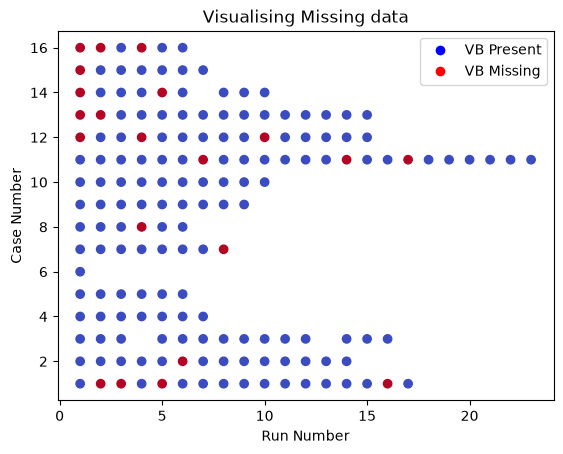

In [6]:
# Task 1b. Insert your code here for plot 1
"""
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

msno.matrix(df)
plt.title("Missing Data Pattern")
plt.show()

df.isnull().sum()
"""
from matplotlib.lines import Line2D
df['Missing_VB'] = df['VB'].isnull()
plt.scatter(
    df['run'],
    df['case'],
    c=df['Missing_VB'],
    cmap='coolwarm', 
)
legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='blue', markersize=8,
           label='VB Present'),

    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='red', markersize=8,
           label='VB Missing')
]
plt.legend(handles=legend_elements)
plt.xlabel('Run Number')
plt.ylabel('Case Number')
plt.title('Visualising Missing data')


runs_cases = list(
    df[['case', 'run', 'VB']]
    .drop_duplicates(subset=['case', 'run'])
    .itertuples(index=False)
)

for case_num in sorted(set(r.case for r in runs_cases)):
    case_runs = [r for r in runs_cases if r.case == case_num]
    df_case = pd.DataFrame({
        "run": [r.run for r in case_runs],
        "VB": [r.VB for r in case_runs],
    })
    print(f"\n=== CASE {case_num} ({len(df_case)} runs) ===")
    print(df_case.to_string(index=False))
    case_dict = {}


In [7]:
for case in sorted(df["case"].unique()):
    runs = sorted(df[df["case"] == case]["run"])

    expected = set(range(min(runs), max(runs) + 1))
    missing = expected - set(runs)

    if missing:
        print(f"Case {case}: Missing runs {sorted(missing)}")

Case 3: Missing runs [4, 13]
Case 14: Missing runs [7]


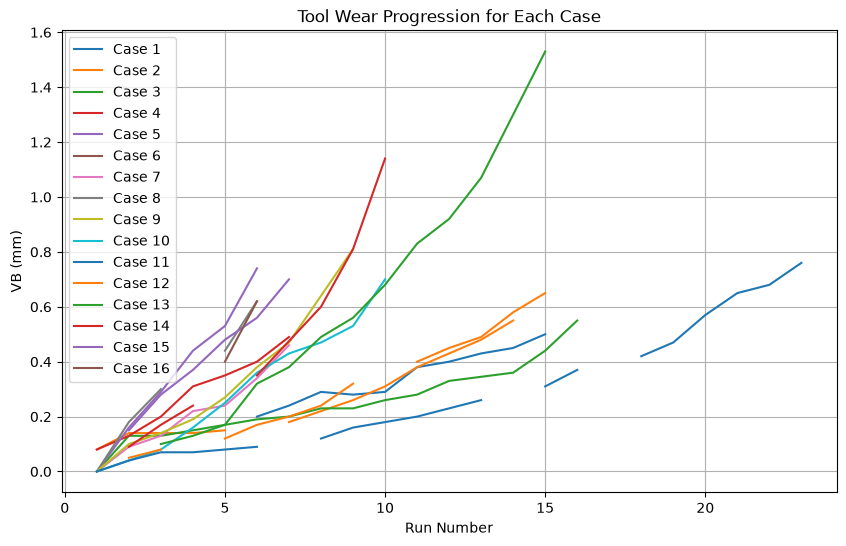

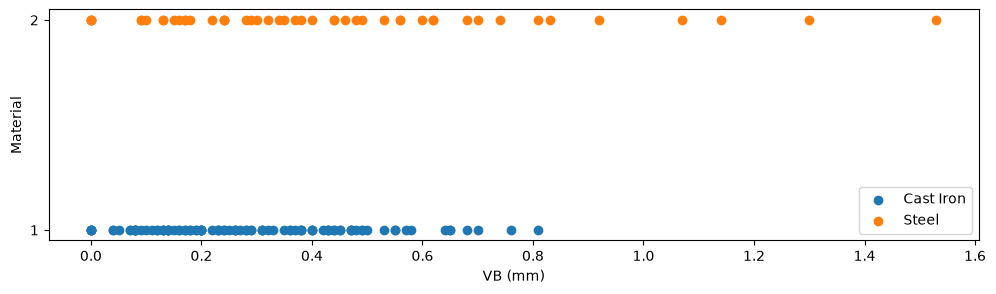

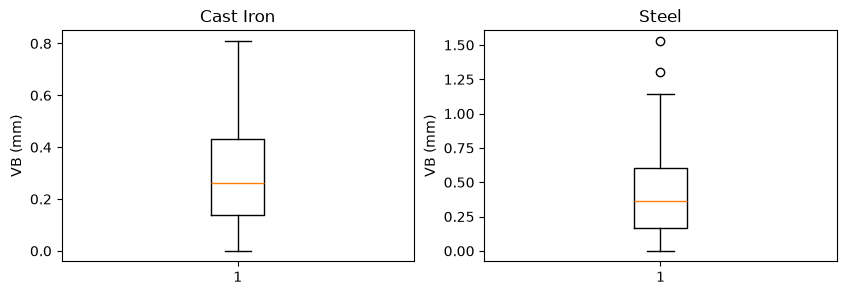

In [8]:
# Insert your code here for plot 2
df_case_runs = pd.DataFrame({
    "case": [r.case for r in runs_cases],
    "run": [r.run for r in runs_cases],
    "VB": [r.VB for r in runs_cases],})
plt.figure(figsize=(10, 6))

for case in sorted(df_case_runs["case"].unique()):
    case_data = (
        df_case_runs[df_case_runs["case"] == case]
        .sort_values("run"))
    plt.plot(
        case_data["run"],
        case_data["VB"],
        #marker="o",
        label=f"Case {case}")

plt.xlabel("Run Number")
plt.ylabel("VB (mm)")
plt.title("Tool Wear Progression for Each Case")
plt.legend()
plt.grid(True)
plt.show()

# Looking at materials and VB

VB_cast_iron = df.loc[df['material'] == 1, 'VB'].tolist()
VB_steel = df.loc[df['material'] == 2, 'VB'].tolist()

n_cast_iron=len(VB_cast_iron)
x_cast_iron = np.full(n_cast_iron, 1)

n_steel=len(VB_steel)
x_steel = np.full(n_steel, 2)

plt.figure(figsize=(12, 3))
plt.scatter(VB_cast_iron,x_cast_iron, label='Cast Iron')
plt.scatter(VB_steel,x_steel,  label='Steel')
plt.yticks([1, 2])
plt.xlabel('VB (mm)')
plt.ylabel('Material')
plt.legend()
plt.show()

# VB and Material Investigation
# Investigating materials

VB_cast_iron = df.loc[df['material'] == 1, 'VB'].dropna().tolist()
VB_steel = df.loc[df['material'] == 2, 'VB'].dropna().tolist()

plt.figure(figsize=(10, 3))
plt.subplot(1,2,1)
plt.boxplot(VB_cast_iron)
plt.ylabel('VB (mm)')
plt.title('Cast Iron')

plt.subplot(1,2,2)
plt.boxplot(VB_steel)
plt.ylabel('VB (mm)')
plt.title('Steel')
plt.show()

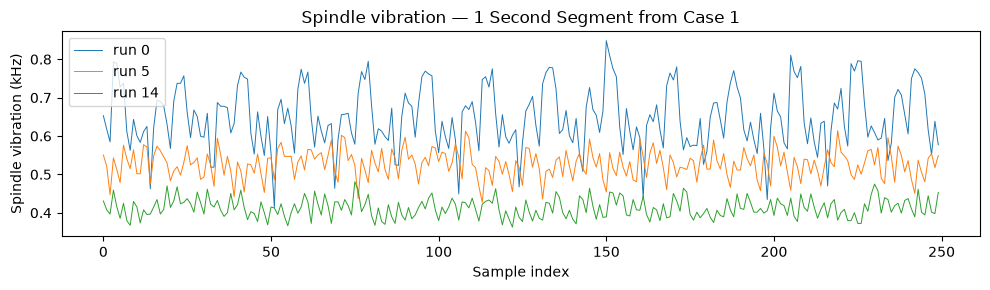

c:\Users\samue\anaconda3\envs\MachineLearning4EngApp\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\samue\anaconda3\envs\MachineLearning4EngApp\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


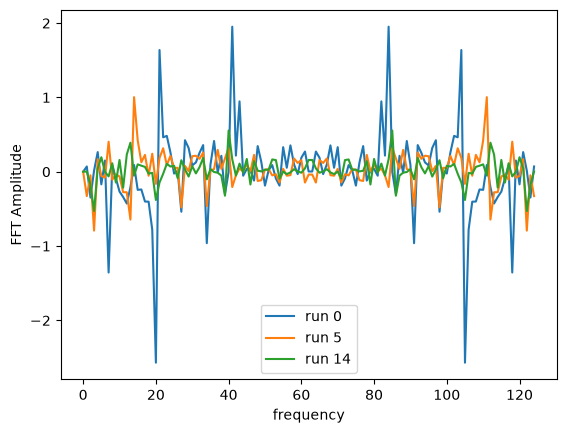

In [9]:
# Insert your code here for plot 3
start_sample=4000
end_sample=4250
test_run_1=0
test_run_2=5
test_run_3=14

vib_spindle_signal_1 = np.asarray(df.at[test_run_1, "vib_spindle"]).ravel()
vib_signal_section_1=signal=vib_spindle_signal_1[start_sample:end_sample]

vib_spindle_signal_2 = np.asarray(df.at[test_run_2, "vib_spindle"]).ravel()
vib_signal_section_2=signal=vib_spindle_signal_2[start_sample:end_sample]

vib_spindle_signal_3 = np.asarray(df.at[test_run_3, "vib_spindle"]).ravel()
vib_signal_section_3=signal=vib_spindle_signal_3[start_sample:end_sample]

plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(vib_signal_section_1)), vib_signal_section_1, linewidth=0.7, label=f"run {test_run_1}")
plt.plot(np.arange(len(vib_signal_section_2)), vib_signal_section_2, linewidth=0.7, label=f"run {test_run_2}")
plt.plot(np.arange(len(vib_signal_section_3)), vib_signal_section_3, linewidth=0.7, label=f"run {test_run_3}")
plt.legend(loc="upper left")
plt.xlabel("Sample index")
plt.ylabel("Spindle vibration (kHz)")
plt.title("Spindle vibration — 1 Second Segment from Case 1")
plt.tight_layout()
plt.show()

from scipy.fft import fft, fftfreq

start_sample_fft=4000
end_sample_fft=4125
test_run_1=0
test_run_2=5
test_run_3=14

vib_spindle_signal_1=np.asarray(df.at[test_run_1, "vib_spindle"]).ravel()
vib_spindle_section_1=vib_spindle_signal_1[start_sample_fft:end_sample_fft]
vib_spindle_mean_1=vib_spindle_section_1-np.mean(vib_spindle_section_1)
vib_fft_1=fft(vib_spindle_mean_1)

vib_spindle_signal_2=np.asarray(df.at[test_run_2, "vib_spindle"]).ravel()
vib_spindle_section_2=vib_spindle_signal_2[start_sample_fft:end_sample_fft]
vib_spindle_mean_2=vib_spindle_section_2-np.mean(vib_spindle_section_2)
vib_fft_2=fft(vib_spindle_mean_2)

vib_spindle_signal_3=np.asarray(df.at[test_run_3, "vib_spindle"]).ravel()
vib_spindle_section_3=vib_spindle_signal_3[start_sample_fft:end_sample_fft]
vib_spindle_mean_3=vib_spindle_section_3-np.mean(vib_spindle_section_3)
vib_fft_3=fft(vib_spindle_mean_3)

plt.plot(vib_fft_1, label=f"run {test_run_1}")
plt.plot(vib_fft_2, label=f"run {test_run_2}")
plt.plot(vib_fft_3, label=f"run {test_run_3}")
plt.xlabel('frequency')
plt.ylabel('FFT Amplitude')
plt.legend()



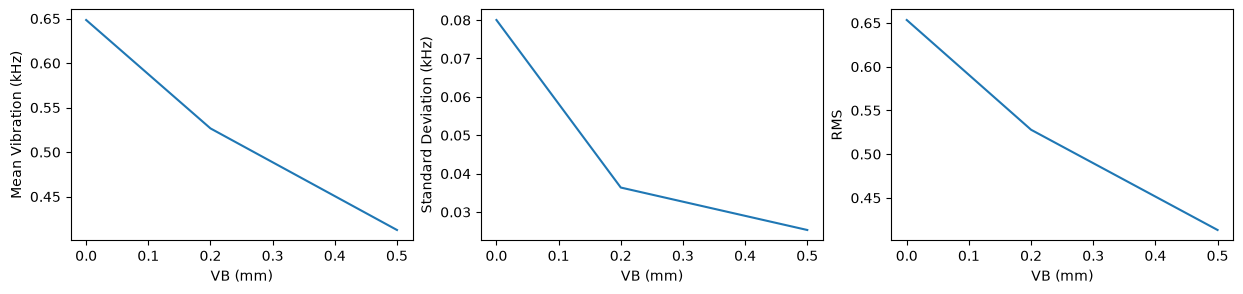

In [10]:
# you may include more plots that may be helpful for analysis
# Calculate SD, mean, RMS and peak for each run in case 1
# Plot each against VB - 4 plots in total woth 3 points each

start_sample=4000
end_sample=4250
test_run_1=0
test_run_2=5
test_run_3=14

# Mean 
vib_spindle_1=np.asarray(df.at[test_run_1, "vib_spindle"]).ravel()
vib_spindle_section_1=vib_spindle_1[start_sample:end_sample]
vib_spindle_mean_1=np.mean(vib_spindle_section_1)

vib_spindle_2=np.asarray(df.at[test_run_2, "vib_spindle"]).ravel()
vib_spindle_section_2=vib_spindle_2[start_sample:end_sample]
vib_spindle_mean_2=np.mean(vib_spindle_section_2)

vib_spindle_3=np.asarray(df.at[test_run_3, "vib_spindle"]).ravel()
vib_spindle_section_3=vib_spindle_3[start_sample:end_sample]
vib_spindle_mean_3=np.mean(vib_spindle_section_3)

vib_spindle_VB_1=np.asarray(df.at[test_run_1, "VB"]).item()
vib_spindle_VB_2=np.asarray(df.at[test_run_2, "VB"]).item()
vib_spindle_VB_3=np.asarray(df.at[test_run_3, "VB"]).item()

x_VB=[vib_spindle_VB_1, vib_spindle_VB_2, vib_spindle_VB_3]
y_mean=[vib_spindle_mean_1, vib_spindle_mean_2, vib_spindle_mean_3]

plt.figure(figsize=(15, 3))
plt.subplot(1,3,1)
plt.plot(x_VB,y_mean)
plt.xlabel('VB (mm)')
plt.ylabel('Mean Vibration (kHz)')

# Standard deviation
vib_spindle_std_1=np.std(vib_spindle_section_1)
vib_spindle_std_2=np.std(vib_spindle_section_2)
vib_spindle_std_3=np.std(vib_spindle_section_3)

y_std=[vib_spindle_std_1, vib_spindle_std_2, vib_spindle_std_3]

plt.subplot(1,3,2)
plt.plot(x_VB,y_std)
plt.xlabel('VB (mm)')
plt.ylabel('Standard Deviation (kHz)')

# RMS
rms_1=np.sqrt(np.mean(vib_spindle_section_1**2))
rms_2=np.sqrt(np.mean(vib_spindle_section_2**2))
rms_3=np.sqrt(np.mean(vib_spindle_section_3**2))

y_rms=[rms_1, rms_2, rms_3]

plt.subplot(1,3,3)
plt.plot(x_VB,y_rms)
plt.xlabel('VB (mm)')
plt.ylabel('RMS')
plt.show()


### Task 1c. <span style="color:red">(10 marks)</span>

-By using your plots from 1b, provide an analysis of the data (e.g. observed patterns, correlations, potential best predictors) and briefly explain how each code snippet supports your evaluation of potential issues with the data (5 marks).

-Once you have done your analysis/insights you should discuss this with your lab tutor (you need to book a slot in lab hours for this), capture that feedback, report it here as well as a reflection of how the feedback informs the next steps of data processing (5 marks).

*Task 1c. Write here your analysis/insights of the EDA, the feedback you received from your tutor and your reflection of how the feedback influences your next steps on the data processing.*

<div class="alert alert-success" style="text-align:left;">
<h2>Task 2. Data Preparation<span style="float:right;">[40 marks]</span></h2></div>

### <span style="color:red">IMPORTANT NOTE: </span> 
This the beginning of your ML building pipeline. All transformations that happen to the data from here onwards may be stateless or stateful. Make a concious decision at which step of the entire process you need to split your data set into training, validation and test set. **Add an additional Code cell** for data splitting when you think it is reasonable to do so as well as **add a Markdown cell** to explain why the data set is splitted at this point of the ML pipeline and the impact data transformation operations might have on the validity of the model if the splitting is not carried out beforehand. You should also justify your train-validation-test splitting stategy.
### <span style="color:red">(8 marks) </span>

### Task 2a. Data Cleaning <span style="color:red">(7 marks)</span>
Using the libraries specificied at the top of the notebook or any other one covered in class, start cleaning your data by handling missing values, handling any duplicates and deal with outliers. Justify your methods.

*Task 2a. Add your justification here*

**METHODOLOGY**

Remove all missing runs.

Remove all first runs that don’t have values.

Interpolate values where there is a value each side.
	


In [ ]:
# Task 2a. Add your code here


hello world


### Task 2b. Data Transformation <span style="color:red">(5 marks)</span>
Perform any necessary normalisation and encoding of categorical variables. Please explain why this step is necessary when building a predictive model and justify the method used.

In [12]:
# Task 2b. Add your code here

*Task 2b. Add your explanation here*

### Task 2c. Data Reduction/Augmentation  <span style="color:red">(10 marks)</span>

Based on your data set implement either data reduction or data augmentation depending on the needs of the problem and data (5 marks). Explain why data reduction or data augmentation is necessary in the context of your engineering problem and the data set you selected as well as justify the methods used (5 marks). One thing to note is that depending on your data set, data reduction might have to be done after Task 2d Feature Engineering, so make sure you apply these two steps (Task 2c and Task 2d) in the correct order according to your data. 

**Note**: If you do have to do 2d before 2c, then just make sure your code is in the correct order in the code cells below.

In [13]:
# Task 2c. Add your code here

*Task 2c. Add your explanation and justification here*

### Task 2d. Feature Engineering   <span style="color:red">(10 marks)</span>

An important aspect of machine learning is understanding the feature space and shaping it before training. That is, preprocessing or reshaping the data in a way that provides more relevant information and an easier job for the regressor or classifier.

Perform any feature engineering that you might think it is ideal for the type of task you are aiming (4 marks). This could include statistical features, rolling window statistics,  frequency analysis (FFT) or any others covered in lectures. 

If either you are going to work directly with the raw data, or you will be engineering features, justify why this is the case in the context of the engineering problem you are trying to solve, justifying any specific features used (3 marks). In the case of raw data, perform any additional transformation that would be needed to work with this raw data directly. 

Assess whether all data is ready for model building. If not, complete the preparation of a model-ready dataframe from your cleaned dataset. More specifically, make sure to assess whether all predictors in your prepared dataframe are directly suitable for the machine learning task, state why this is the case  and state what(if anything) still needs processing, and process / make the necessary adjustment in the data accordingly (3 marks).

In [14]:
# Task 2c. Add your code here

Task 2c. Add your explanations/justifications here

<div class="alert alert-success" style="text-align:left;">
<h2>Task 3. ML Model Building<span style="float:right;">[35 marks]</span></h2></div>

### Task 3a. Building a base  model <span style="color:red">(10 marks)</span>

Now, after meeting your tutor for the second time to discuss your preliminary model selection and reasons for such method (you need to book again a slot during your lab for this) select and build a baseline model from scratch (e.g. define architecture in the case of NN) to predict or classify according to your problem using the preprocessed dataset. 

- Train the model and report **three different** evaluation metrics (3 marks).
- Reflecting from  your tutor feedback, explain how this feedback influenced the ML model selected, why is it appropriate for the task? why the hyper-parameters used? (4 marks)
- For each metric, explain (in a single short sentence) why it is relevant and whether the observed value suggests sensible predictions/classifications, i.e. what the values within the metric mean (3 marks). 

In [15]:
#Add your code here

Add your justification for metrics here and what the results obtained mean.

### Task 3b. Hyper-parameter exploration <span style="color:red">(10 marks)</span>

You have now build a base model, with some initial results. It is now your task to experiment with hyper-parameters (5 marks) to see if you can improve the quality of your results. It is up to you how you approach this process, but you need to justify (5 marks ) the approach you are taking and discuss the results. What effect is having the changes you are doing to the approach?

In [16]:
#perform your different hyper-parameter optimisation/changes here

Add here your justification for how you are approaching the hyper-parameter tuning  and discuss your results.

### Task 3c. Additional Models and Final Analysis <span style="color:red">(15 marks)</span>

Implement at least one more method of your choice.Report model quality with clear evidence (metrics). Compare with the baseline using supportive tables or visualisations (4 marks), and discuss the strengths and limitations of each (3 marks). Finally, provide a discussion (8 marks) on:

Why this type of model and would you deploy it in a real environment? why?

Under what operating conditions would you not trust it? how could you improve it?

What additional sensor would you collect and why?

Are the important features physically plausible?

In [17]:
# your implementaiton of additional methods here together with metrics

Add here your discussion on strengths and limitations of each method